# DINO-WM: world models on frozen features, then used to plan

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/dinowm.ipynb)

[DINO-WM](https://arxiv.org/abs/2411.04983) ([code](https://github.com/gaoyuezhou/dino_wm)) leaves the visual encoder frozen (DINOv2 patch features) and learns only the dynamics: a ViT predictor with frame-level causal attention, plus small action and proprioception encoders. Planning then runs in the frozen feature space.

Two worlds, both simulated in [MuJoCo](https://mujoco.org) (`pip install torch-world[action]`):
1. a **Universal Robots UR10e** arm with a Robotiq 2F-85 gripper and a cube, after [OGBench](https://github.com/seohongpark/ogbench) `cube-single`;
2. **Push-T**, pushing a T-shaped block into a goal pose: the paper's benchmark, reproduced with the paper's model, DINOv2 features, data and evaluation protocol.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples,action]"

In [1]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, metrics, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import PushT, RobotCube
from torch_world.models import DINOWM
from torch_world.nn import PatchTokens, PixelPatches
from torch_world.planning import CEM, RecedingHorizon

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Frozen encoder
With internet access, use DINOv2: `encoder = PatchTokens.from_hub("dinov2_vits14")`. To stay self-contained and fast, this notebook uses raw 16×16 pixel patches as the frozen features (`PixelPatches`), so predicted latents can be viewed as images.

In [2]:
encoder = PixelPatches(16)
HISTORY = 3


def train(model, loader, epochs):
    opt = torch.optim.AdamW(model.parameters(), lr=5e-4)
    log = {"visual": [], "proprio": []}
    for epoch in range(epochs):
        for batch in loader:
            out = model(batch["pixels"], batch["actions"], batch["proprio"])
            opt.zero_grad()
            out["loss"].backward()
            opt.step()
            log["visual"].append(out["visual_loss"].item())
            log["proprio"].append(out["proprio_loss"].item())
    return model.eval(), log

## Part 1 · UR10e arm
### Play data
A noisy scripted policy picks the cube up and puts it down at random spots, like OGBench's `play` datasets. Actions move the gripper by up to 10 cm and open or close it, five times a second; proprioception is the gripper position and opening.

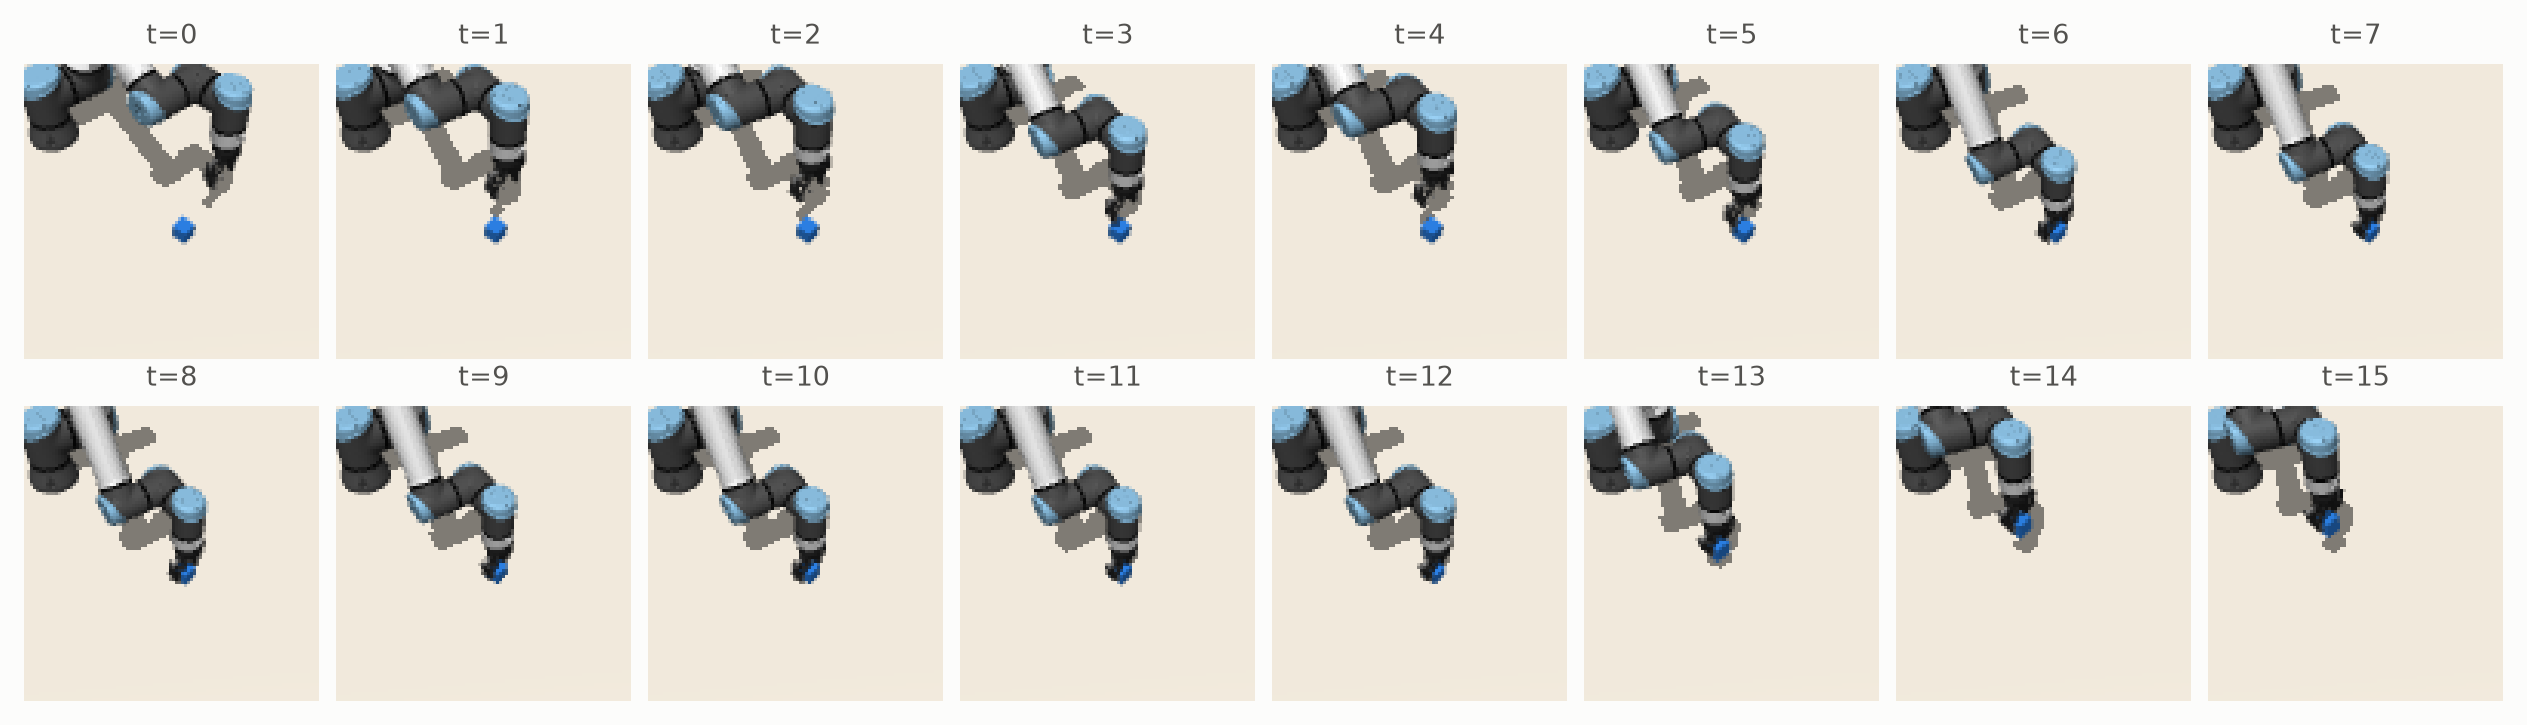

In [3]:
ROBOT = dict(robot="ur10e", size=96, control_dt=0.2, max_step=0.1)
data = {k: v.to(device) for k, v in RobotCube(batch_size=1024, **ROBOT).collect(24, generator=torch.Generator().manual_seed(0)).items()}
data["proprio"] = data["states"][..., :4]
plots.images(data["pixels"][2, :16].cpu(), [f"t={t}" for t in range(16)], size=1.3)

19.49M trainable parameters


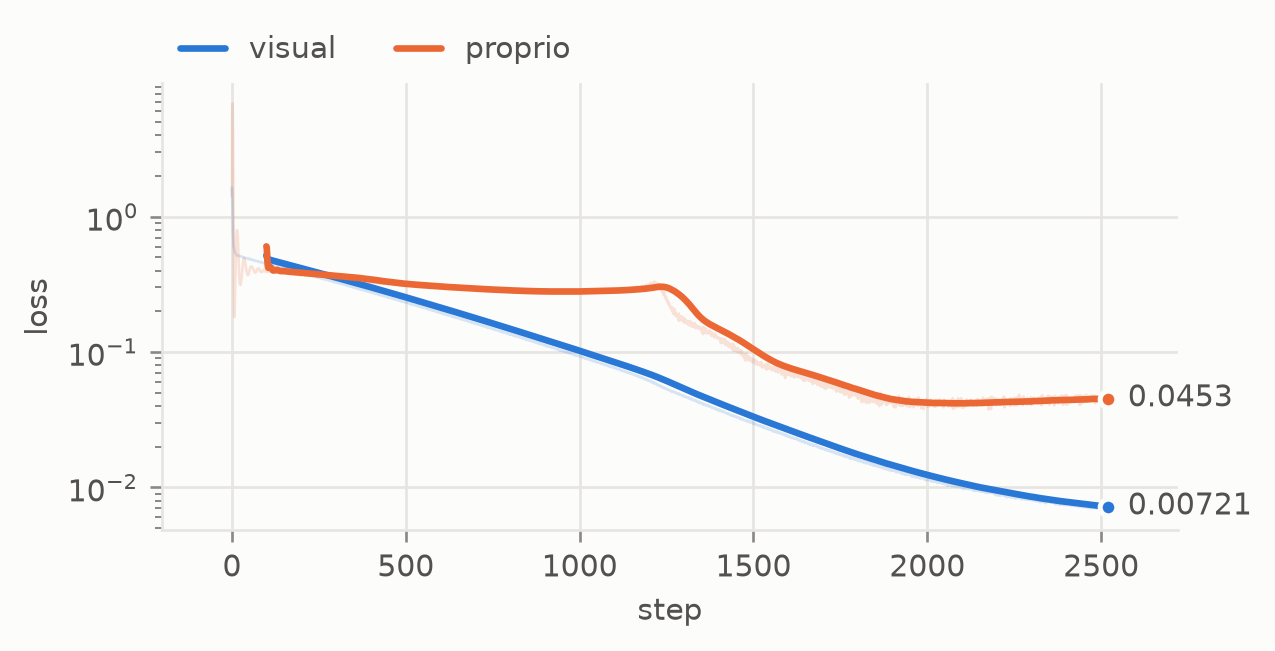

In [4]:
arm = DINOWM(encoder, num_patches=36, embed_dim=encoder.dim, action_dim=4, proprio_dim=4, history=HISTORY, depth=6, num_heads=8, head_dim=64, mlp_dim=1024).to(device)
print(f"{sum(p.numel() for p in arm.parameters() if p.requires_grad) / 1e6:.2f}M trainable parameters")
arm, log = train(arm, DataLoader(TrajectoryDataset(data, HISTORY + 1), batch_size=256, shuffle=True, drop_last=True), 30)
plots.curves(log, smooth=100)

### Imagination
From one real frame, the model unrolls the expert's pick-and-place actions in feature space without seeing any more frames. Pixel-patch features decode exactly to images, so imagined frames are scored against the real ones with the image metrics DINO-WM reports for its decoded predictions: SSIM (1 is identical) and PSNR, over 64 held-out episodes.

step         0     2     4     6     8    10
SSIM     1.000 0.732 0.717 0.697 0.671 0.660
PSNR dB  120.0  19.1  17.6  16.8  16.1  15.5


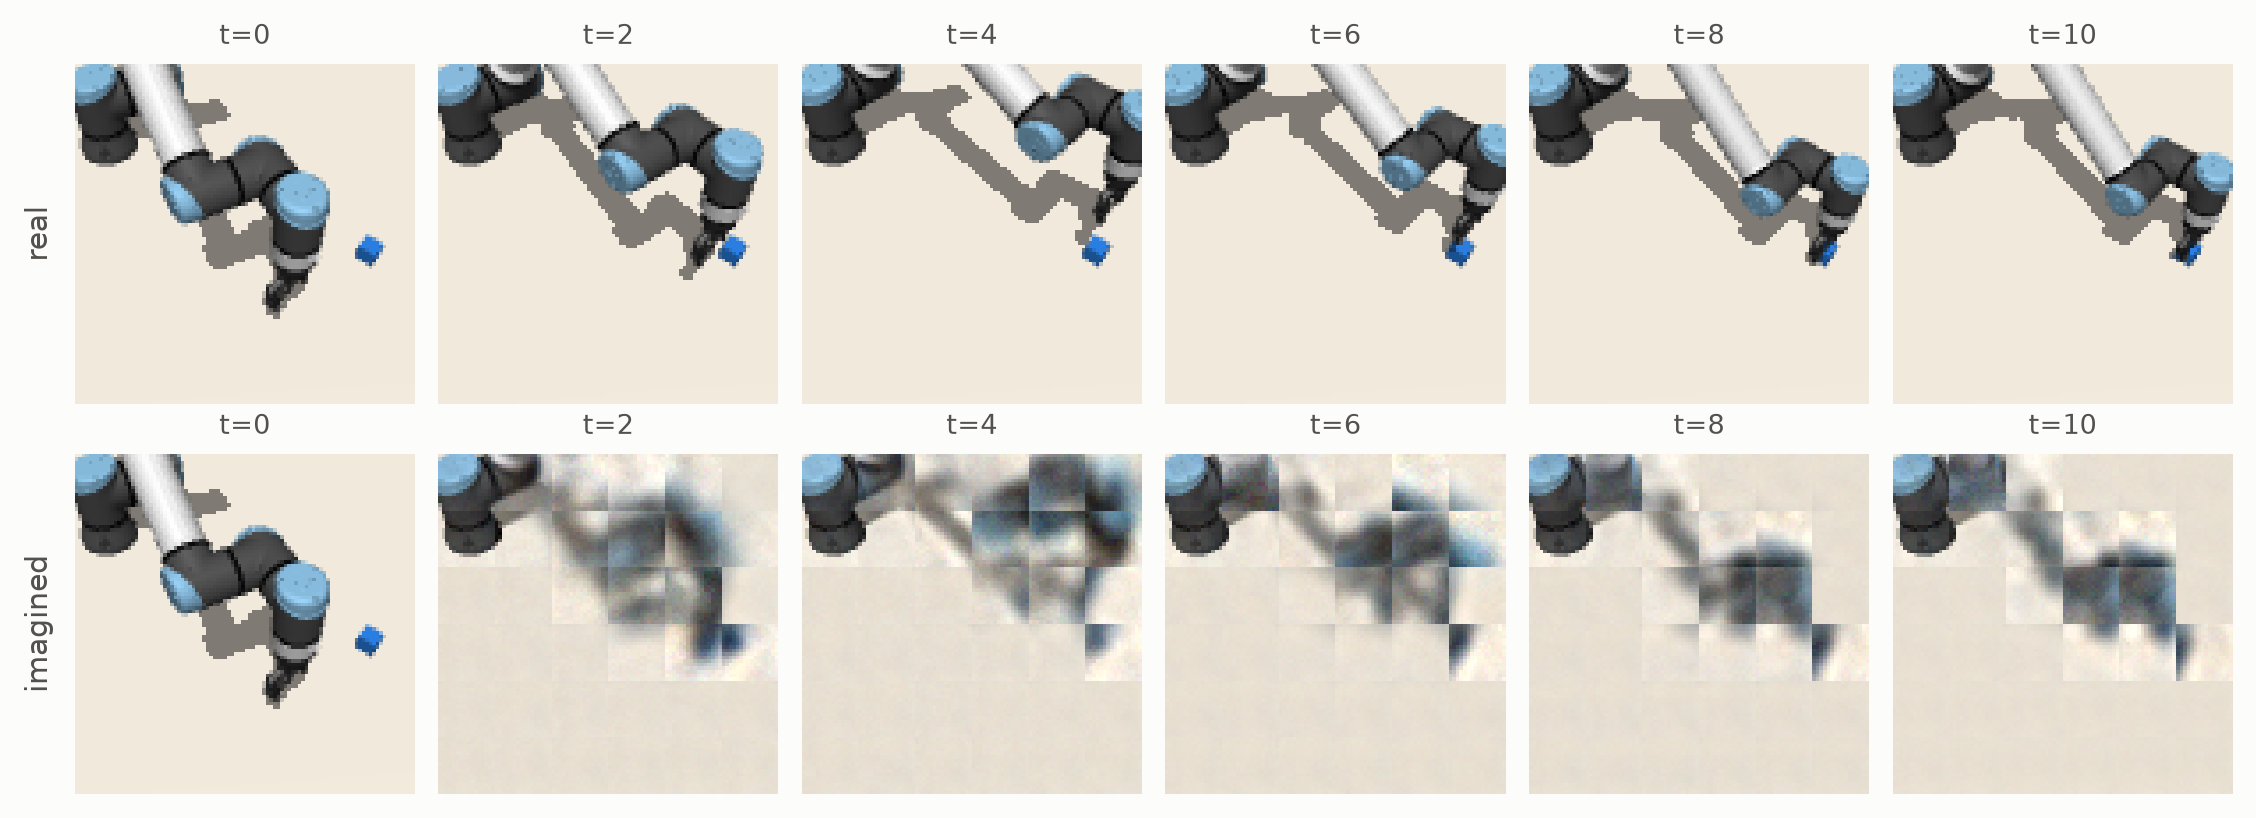

In [5]:
env = RobotCube(batch_size=64, **ROBOT)
first = env.reset(generator=torch.Generator().manual_seed(5))
target = env.sample_targets(generator=torch.Generator().manual_seed(6))
s0, real, actions = env.state.clone(), [first], []
for t in range(10):
    actions.append(env.expert(target))
    real.append(env.step(actions[-1]))
real = torch.stack(real, 1)
with torch.no_grad():
    z = arm.rollout(arm.encode(first[:, None].to(device), s0[:, None, :4].to(device)), torch.stack(actions, 1).to(device))
imagined = encoder.unpatchify(z.flatten(0, 1), (6, 6)).unflatten(0, z.shape[:2]).clamp(0, 1).cpu()
ssim, psnr = metrics.ssim(imagined, real).mean(0), metrics.psnr(imagined, real).mean(0)
print("step    " + "".join(f"{t:>6d}" for t in range(0, 11, 2)))
print("SSIM    " + "".join(f"{v:6.3f}" for v in ssim[::2].tolist()))
print("PSNR dB " + "".join(f"{v:6.1f}" for v in psnr[::2].tolist()))
keep = list(range(0, 11, 2))
plots.images(torch.cat([real[0, keep], imagined[0, keep]]), ncols=len(keep), size=1.5, rows=["real", "imagined"], titles=[f"t={t}" for t in keep] * 2)

### Plan toward goal images
Each task gives a start and the image of a goal state. CEM searches 5-step action sequences in feature space and MPC executes the first action of each plan. The `"path"` objective scores every imagined step, not only the last, so the planner moves now instead of postponing its moves to the end of the horizon.

Two tasks:
- **reach**: move the open gripper to the pose in the goal image; success within 5 cm.
- **pick and place**: carry the cube to the spot in the goal image (OGBench `cube-single`); success when the cube rests within 5 cm of it.

The scripted expert and random actions bracket the planner.

Each policy gets the standard measures of goal reaching: the final **success** rate with its 95% Wilson interval (16 episodes leave wide intervals), the share of episodes that **reached** the goal at any step and the mean **steps** to get there, the median **final distance** (meters), the median **progress** (fraction of the start distance closed), **SPL** (success weighted by how direct the path was), action **smoothness** (mean change between consecutive actions; lower is smoother) and the planning time per step.

== reach
                           success  reached   steps  final distance  progress     SPL  smoothness  ms / step
DINO-WM + CEM        19% [7%, 43%]      50%    5.12           0.132     0.434  0.0857       0.623   7.95e+04
scripted expert   100% [81%, 100%]     100%    2.56        6.01e-08         1   0.969       0.151      0.108
random actions        0% [0%, 19%]       6%       3           0.283    -0.121       0        1.56     0.0757


== pick and place
                           success  reached   steps  final distance  progress     SPL  smoothness  ms / step
DINO-WM + CEM         0% [0%, 19%]       0%     nan           0.191         0       0       0.545   7.95e+04
scripted expert   100% [81%, 100%]     100%    12.1         0.00115     0.991   0.939       0.487      0.295
random actions        0% [0%, 19%]       0%     nan           0.194         0       0        1.55     0.0859


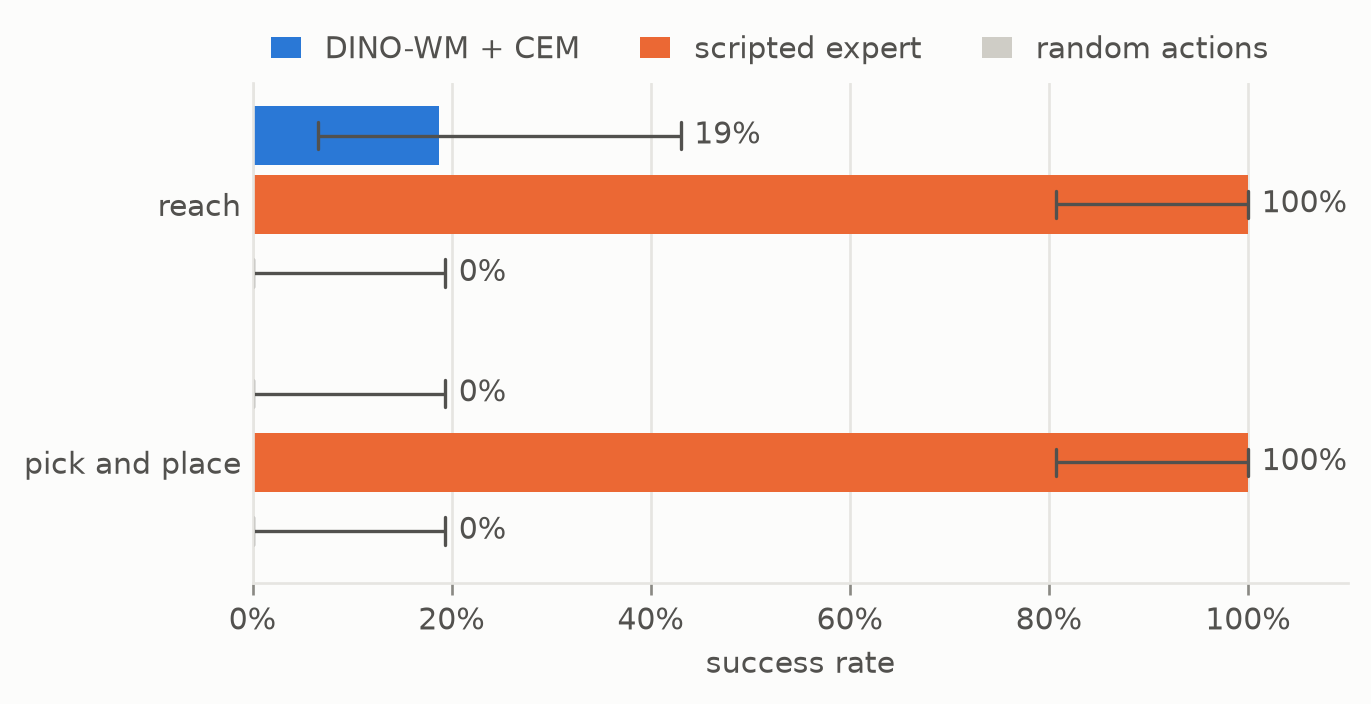

In [6]:
def plan_with(model, env, goal_state, proprio, action_dim):
    with torch.no_grad():
        goal = model.encode(env.render(goal_state)[:, None].to(device), goal_state[:, None, proprio].to(device))[:, 0]
    planner = CEM(horizon=5, action_dim=action_dim, num_samples=256, num_elites=32, iterations=10, bounds=(-1, 1), objective="path")
    return lambda obs: planner(model, model.encode(obs[:, None].to(device), env.state[:, None, proprio].to(device)), goal)[:, 0].cpu()


arm_runs = {}
for task, steps in [("reach", 12), ("pick and place", 30)]:
    env = RobotCube(batch_size=16, task=task.split()[0], **ROBOT)
    start, goal_state = env.tasks(generator=torch.Generator().manual_seed(1))
    policies = {"DINO-WM + CEM": plan_with(arm, env, goal_state, slice(0, 4), 4), "scripted expert": lambda obs, env=env, goal_state=goal_state: env.scripted(goal_state), "random actions": evaluation.random_policy(env)}
    arm_runs[task] = evaluation.goal_reaching(env, policies, start, goal_state, steps, record=lambda e, goal_state=goal_state: e.render(size=160, goal=goal_state))
    print(f"== {task}\n{arm_runs[task]}")
plots.bars({task: r.intervals() for task, r in arm_runs.items()}, xlabel="success rate", baseline="random actions")

Reaching episodes of the planner. The translucent orange gripper marks the goal (videos only; the model sees the plain scene):


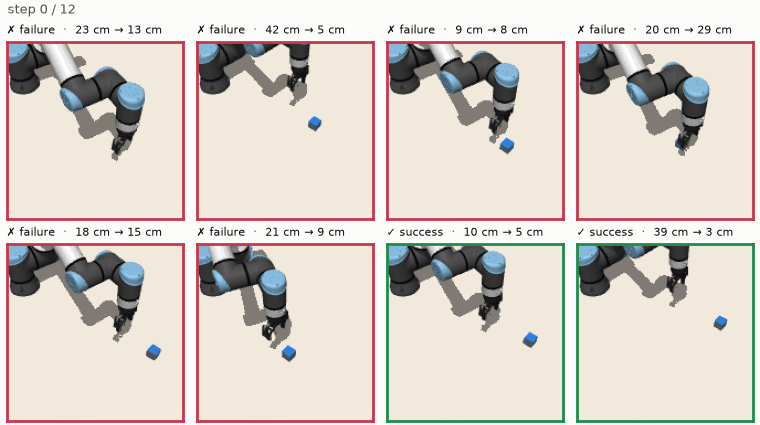

In [7]:
r = arm_runs["reach"]
plots.episodes(r.frames["DINO-WM + CEM"][:8], r.success["DINO-WM + CEM"][:8], [f"{100 * d:.0f} cm → {100 * e:.0f} cm" for d, e in r.distances["DINO-WM + CEM"][:8, [0, -1]].tolist()])

Pick and place is where greedy latent planning breaks down. The planner reaches the arm pose shown in the goal image, but carrying the cube needs a detour (descend, grasp, lift, carry) that a short horizon never finds attractive, and the cube covers only a few patches. The paper reaches such tasks with pre-trained DINOv2 features, more data and longer horizons; here the expert and planner videos show the gap:


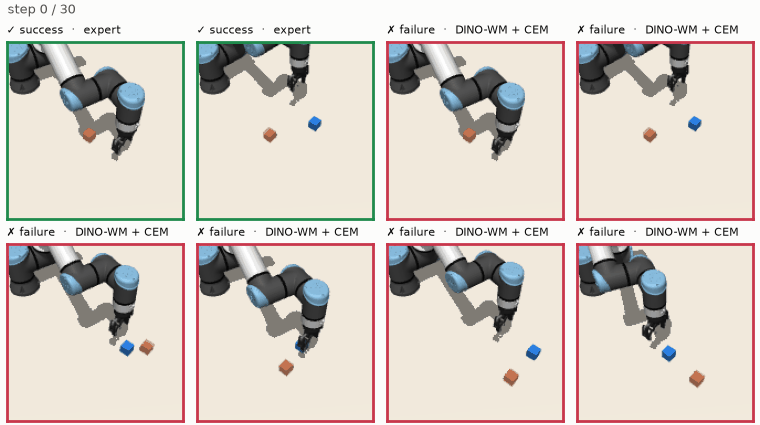

In [8]:
r = arm_runs["pick and place"]
plots.episodes(torch.cat([r.frames["scripted expert"][:2], r.frames["DINO-WM + CEM"][:6]]), torch.cat([r.success["scripted expert"][:2], r.success["DINO-WM + CEM"][:6]]), ["expert"] * 2 + ["DINO-WM + CEM"] * 6)

## Part 2 · Push-T, reproducing the paper
`PushT` follows the paper's Push-T (stable-worldmodel's `swm/PushT-v1`): the same arena, T block, pusher, dynamics and success test, in MuJoCo (see the LeWM notebook).

The model is stable-worldmodel's DINO-WM: frozen **DINOv2 ViT-S/14** patch features (256 per 224 px frame), with proprioception (the pusher's position and velocity) and action embeddings on every patch, and a frame-causal ViT predictor. It was trained with that recipe on the paper's 18,685 expert episodes replayed in this env, outside the notebook. Here we load it from `checkpoints/` and evaluate it on the paper's tasks: each start is a state of an expert episode, and its goal the state the expert reached 25 steps later.

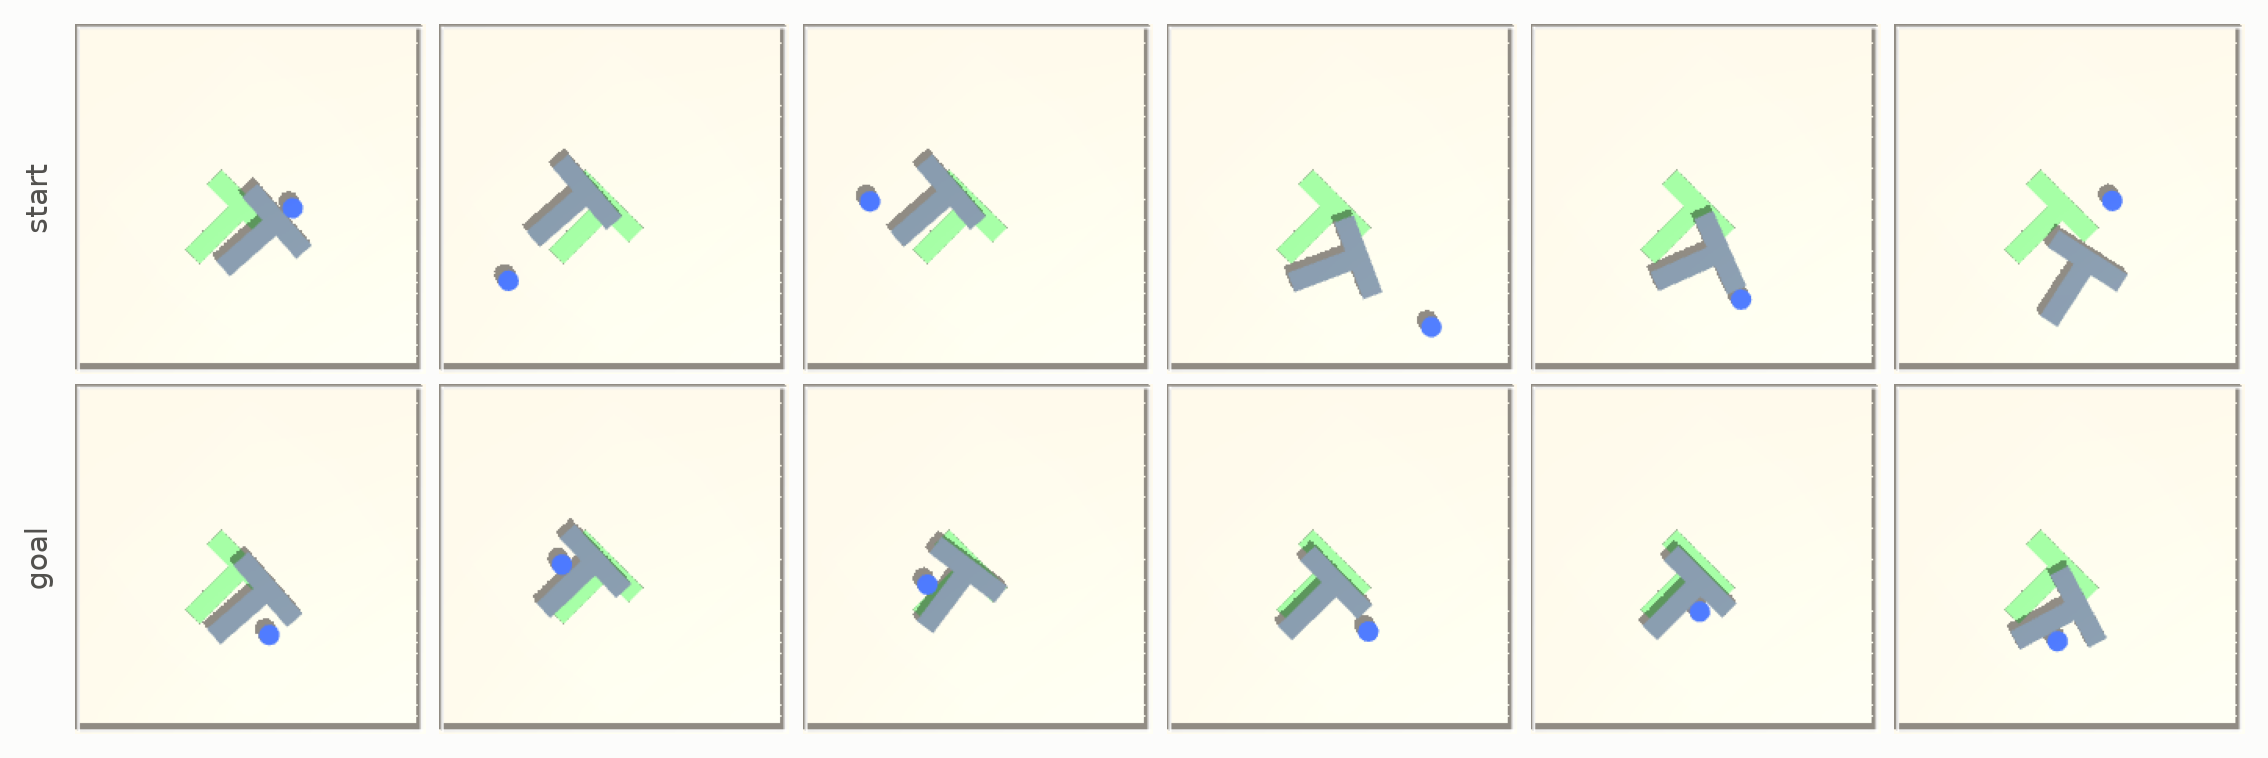

In [9]:
tasks = torch.load("checkpoints/pusht_expert_tasks.pt")  # start and goal states, (500, 7) each
env = PushT(batch_size=50, size=224)
plots.images(torch.cat([env.render(tasks["start"][:6]), env.render(tasks["goal"][:6])]).cpu(), ncols=6, size=1.5, rows=["start", "goal"])

In [10]:
CHECKPOINT = "checkpoints/dinowm_pusht_mj.pt"  # the trained DINOWM state dict, without the frozen encoder (loaded from torch hub)
dino = PatchTokens.from_hub("dinov2_vits14", size=None)
pt = DINOWM(dino, num_patches=256, embed_dim=dino.dim, action_dim=10, proprio_dim=4, history=HISTORY, depth=6, num_heads=16, head_dim=64, mlp_dim=2048).to(device)
missing, unexpected = pt.load_state_dict(torch.load(CHECKPOINT, map_location=device), strict=False)
assert not unexpected and all(k.startswith("encoder.") for k in missing)
pt.eval()
print(f"{sum(p.numel() for p in pt.parameters() if p.requires_grad) / 1e6:.1f}M trained parameters on a frozen {sum(p.numel() for p in dino.parameters()) / 1e6:.1f}M encoder")

20.2M trained parameters on a frozen 22.1M encoder


### Evaluate with the paper's protocol
As stable-worldmodel's `eval_wm.py`: the model plans in the z-scored action space of its training data, with z-scored proprioception. CEM samples 300 plans of 5 blocks of 5 actions, refits to the 30 cheapest for 30 iterations, and scores a plan by the distance between its last imagined features and the goal's (visual features plus proprioception, DINO-WM's cost). The policy executes the whole plan, 25 steps, before planning again; each episode gets 50 steps, and succeeds when the goal is **reached** at any step. Each task is planned on its own, as in the reference: 300 candidates × 3 frames × 256 patches fill the GPU.

The expert data keeps the reference's axes and units (pixels, y down), so proprioception is read in those units and plans flip y before they reach the env.

                          success  reached   steps  final distance  progress  smoothness  ms / step  coverage
DINO-WM + CEM      92% [81%, 97%]      92%    22.8          0.0038     0.826       0.256   1.21e+05       88%
random actions        0% [0%, 7%]       0%     nan          0.0309         0        1.04     0.0914       48%

reached the goal (paper's success): DINO-WM + CEM 92% [81%, 97%]   random actions 0% [0%, 7%]


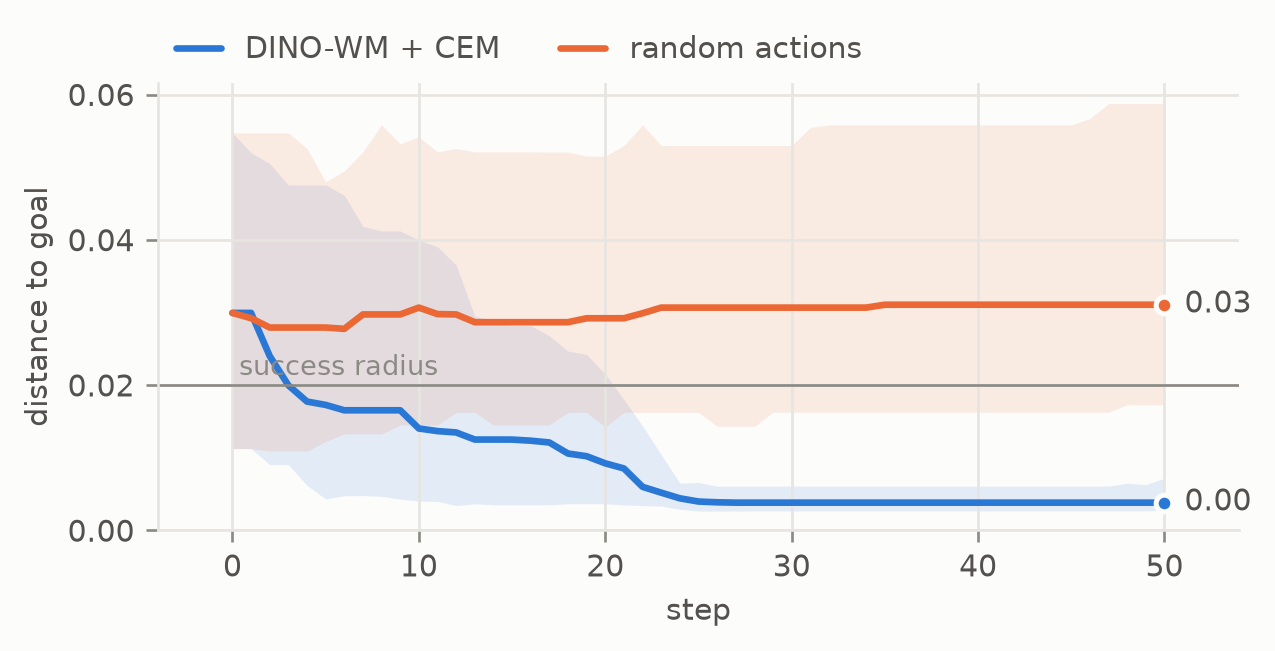

In [11]:
ACTION_MEAN, ACTION_STD = torch.tensor([-0.0078, 0.0069]), torch.tensor([0.2082, 0.2065])  # of the expert data
PROPRIO_MEAN, PROPRIO_STD = torch.tensor([228.34, 292.22, -2.97, 2.55]), torch.tensor([103.32, 98.90, 77.07, 76.68])
FLIP_Y = torch.tensor([1.0, -1.0])
pt_planner = CEM(horizon=5, action_dim=10, num_samples=300, num_elites=30, iterations=30)


def embed(model, images, states):
    proprio = PushT.to_reference(states.double().cpu())[:, [0, 1, 5, 6]].float()  # pusher position and velocity
    with torch.autocast(device, torch.bfloat16):
        return model.encode(images.to(device)[:, None], ((proprio - PROPRIO_MEAN) / PROPRIO_STD).to(device)[:, None]).float()


def plan_pusht(model, env, goal_state):
    with torch.no_grad():
        goal = embed(model, env.render(goal_state), goal_state)[:, 0]

    def plan(obs):
        z = embed(model, obs, env.state)
        with torch.autocast(device, torch.bfloat16):
            blocks = torch.cat([pt_planner(model, z[i : i + 1], goal[i : i + 1]) for i in range(len(z))]).float().cpu()
        return ((blocks.unflatten(-1, (5, 2)) * ACTION_STD + ACTION_MEAN) * FLIP_Y).flatten(-2)

    return RecedingHorizon(plan, action_dim=2, execute=5)


start, goal_state = tasks["start"][:50], tasks["goal"][:50]
policies = {"DINO-WM + CEM": plan_pusht(pt, env, goal_state), "random actions": evaluation.random_policy(env)}
pt_run = evaluation.goal_reaching(env, policies, start, goal_state, steps=50, record=lambda e: e.render(size=160, goal=goal_state))
pt_success = {name: metrics.success_rate(r[:, 1:].any(1)) for name, r in pt_run.reached.items()}  # the paper's measure
print(pt_run)
print("\nreached the goal (paper's success):", "   ".join(f"{name} {rate}" for name, rate in pt_success.items()))
plots.distances(pt_run.distances, radius=env.radius)

Episodes of the planner. The green T is the target drawn in every frame, as in the paper's renders; the translucent orange T marks this episode's goal (videos only):


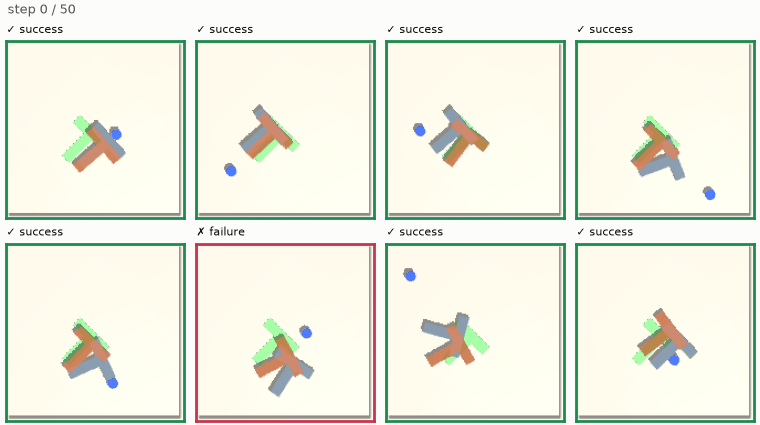

In [12]:
won = pt_run.reached["DINO-WM + CEM"][:, 1:].any(1)
plots.episodes(pt_run.frames["DINO-WM + CEM"][:8], won[:8])

Where the T went (the path darkens over time), from above:

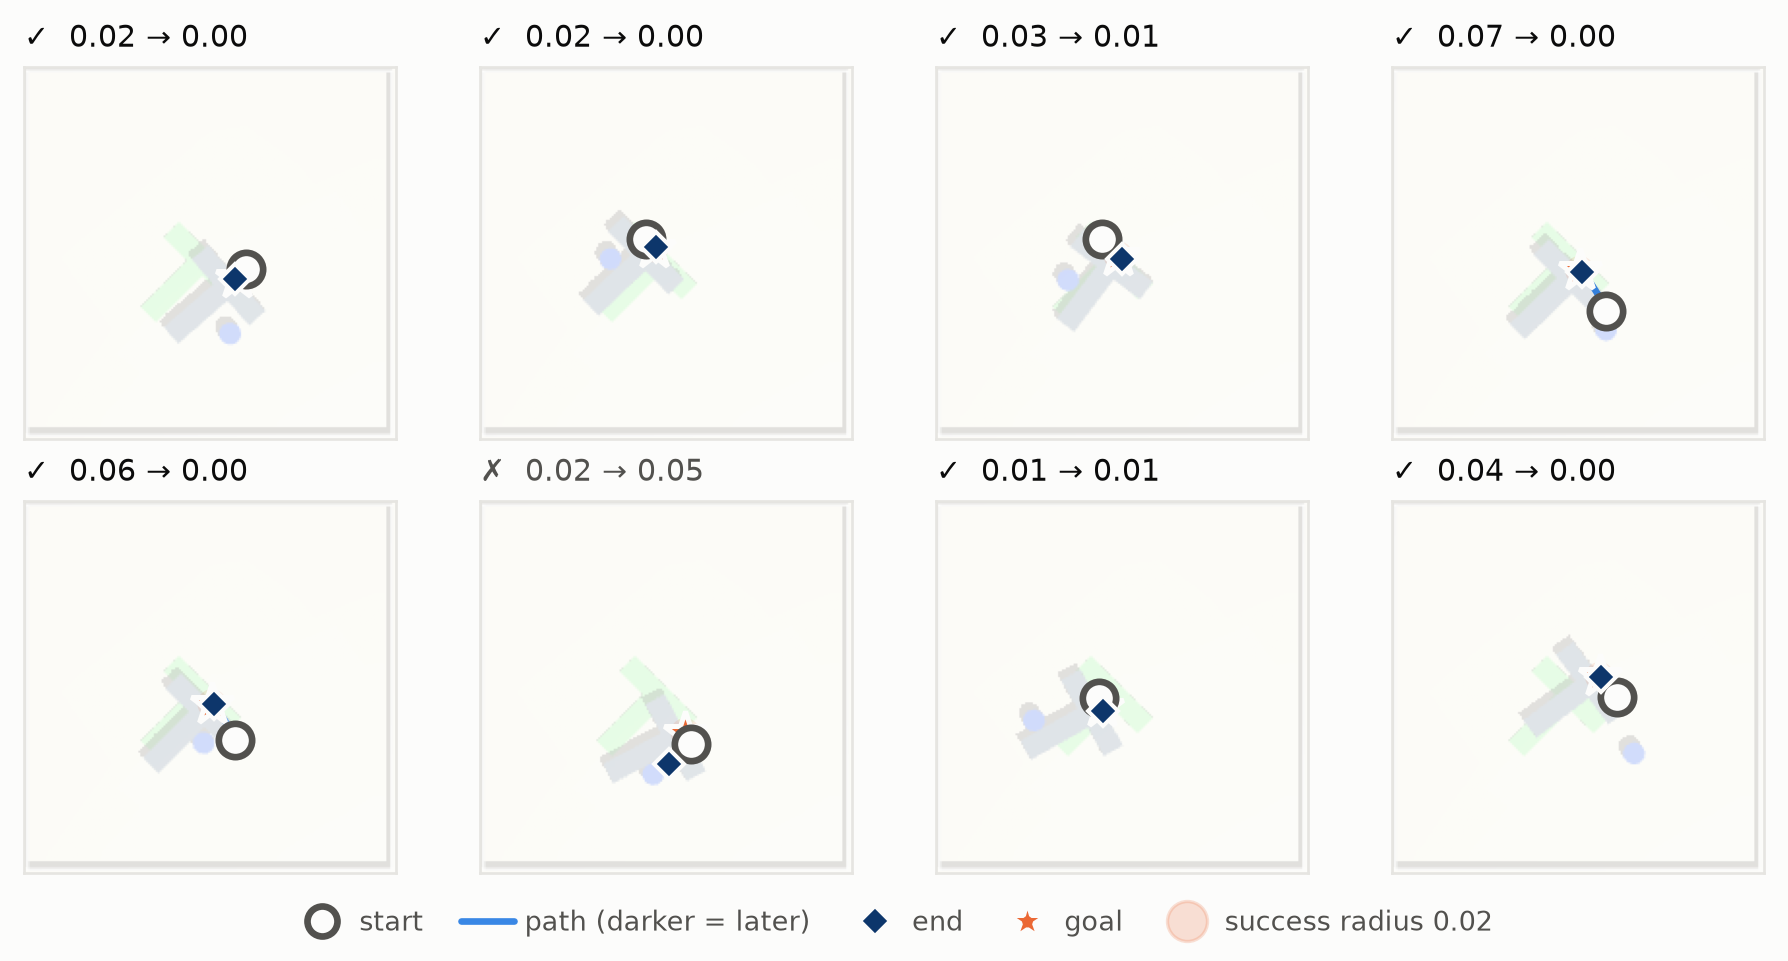

In [13]:
paths = pt_run.paths["DINO-WM + CEM"][:8]
plots.trajectories(env.position(paths), env.position(goal_state[:8]), radius=env.radius / env.top_size, scale=env.top_size, background=env.render(goal_state[:8], camera="top", size=192), success=won[:8])

## Summary
Arm tasks score the final step; Push-T scores reaching the goal at any step, as the paper does.

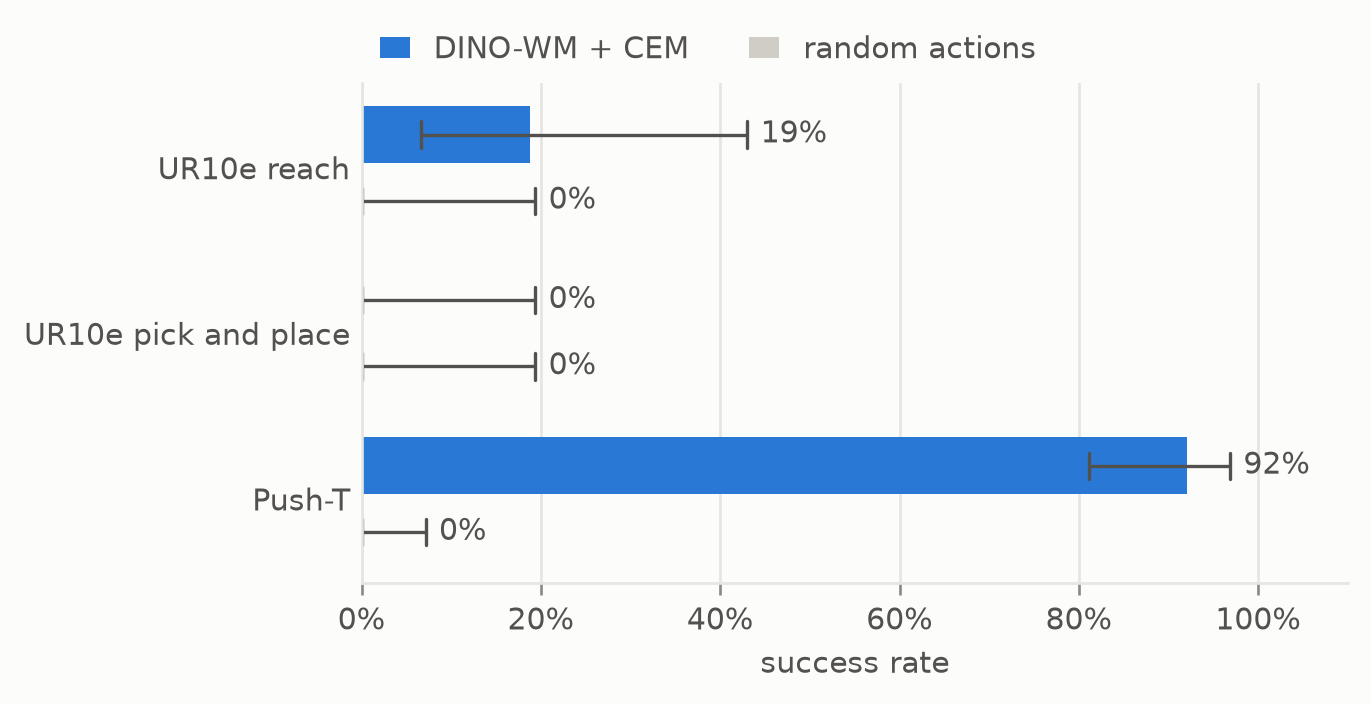

In [14]:
results = {"UR10e reach": arm_runs["reach"].intervals(), "UR10e pick and place": arm_runs["pick and place"].intervals(), "Push-T": pt_success}
plots.bars({name: {k: r[k] for k in ("DINO-WM + CEM", "random actions")} for name, r in results.items()}, xlabel="success rate", baseline="random actions")